# Jigsaw puzzle

The task is to reconstruct a complete RGB image of size 96×96 from a set of 9 scrambled image patches of size 28×28×3. The patches originate from a 3×3 partition of the original image, but their spatial arrangement is unknown and part of the border information has been removed through erosion, making the reconstruction problem ambiguous. The model must therefore infer both the correct relative placement of the patches and the missing visual content required to produce a coherent, artifact-free reconstruction of the original image.

In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import keras
from keras import layers, models
from keras.utils import PyDataset
import tensorflow as tf

We use the stanford stl10 dataset, containng 100K color images at resolution (96,96), covering 10 classes: airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck.

Downloading the dataset is time consuming. We recommend to save a local copy.

In [ ]:
def download_and_load_stl10():
    # Download and extract the dataset
    path = tf.keras.utils.get_file(
        'stl10_binary.tar.gz',
        origin='http://ai.stanford.edu/~acoates/stl10/stl10_binary.tar.gz',
        extract=True
    )

    # Get the base directory (typically ~/.keras/datasets/)
    base_dir = os.path.dirname(path)

    # Based on your error, we navigate to the extracted subfolder
    data_dir = os.path.join(base_dir, 'stl10_binary_extracted', 'stl10_binary')
    filepath = os.path.join(data_dir, 'unlabeled_X.bin')

    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Could not find the binary file at {filepath}")

    print(f"Loading data from: {filepath}")

    # Read-only, disk-backed data: do not load or normalize the whole dataset.
    image_bytes = 3 * 96 * 96
    if os.path.getsize(filepath) != 100_000 * image_bytes:
        raise ValueError("Expected the complete STL-10 unlabeled binary file.")
    data = np.memmap(filepath, dtype=np.uint8, mode="r", shape=(100_000, 3, 96, 96))
    # Preserve STL-10's original axis ordering; this transpose is a view.
    images = data.transpose(0, 3, 2, 1)

    return images

class PatchGenerator(PyDataset):
    def __init__(self, images, batch_size=32, patch_size=32, crop_size=28, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.images = images  # Keep uint8 data; normalize only requested images.
        self.batch_size = batch_size
        self.patch_size = patch_size
        self.crop_size = crop_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.images))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        actual_batch_size = len(batch_indices)

        # X: (Batch, 9 patches, 28, 28, 3)
        # Y: (Batch, 96, 96, 3), normalized reconstruction target
        X = np.zeros((actual_batch_size, 9, self.crop_size, self.crop_size, 3), dtype="float32")
        Y = np.zeros((actual_batch_size, 96, 96, 3), dtype="float32")

        for i, img_idx in enumerate(batch_indices):
            full_img = self.images[img_idx].astype("float32")
            full_img /= 255.0
            Y[i] = full_img
            patches = []

            # Extract 9 patches in a 3x3 grid
            for r in range(3):
                for c in range(3):
                    # Define grid coordinates
                    y_start, x_start = r * self.patch_size, c * self.patch_size
                    patch = full_img[y_start : y_start + self.patch_size,
                                     x_start : x_start + self.patch_size, :]

                    # Center Crop to avoid edge-matching shortcuts (we could go random crop)
                    margin = (self.patch_size - self.crop_size) // 2
                    patch = patch[margin : margin + self.crop_size,
                                  margin : margin + self.crop_size, :]
                    patches.append(patch)

            # Create a permutation (0-8)
            order = np.random.permutation(9)

            for slot_idx, original_pos in enumerate(order):
                X[i, slot_idx] = patches[original_pos]

        return X, Y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

In [ ]:
# Trigger the download and loading
images = download_and_load_stl10()
print(f"Successfully loaded {images.shape[0]} images.")

2640397119/2640397119 ━━━━━━━━━━━━━━━━━━━━ 544s 0us/step
Loading data from: /root/.keras/datasets/stl10_binary_extracted/stl10_binary/unlabeled_X.bin
Successfully loaded 100000 images.


In [ ]:
print(images.shape)

(100000, 96, 96, 3)


In [ ]:
train_images = images[:80000]
val_images = images[80000:90000]
test_images = images[90000:]

In [ ]:
train_generator = PatchGenerator(train_images, batch_size=32)
val_generator = PatchGenerator(val_images, batch_size=32, shuffle=False)
test_generator = PatchGenerator(test_images, batch_size=32, shuffle=False)


Let us inspect the dataset.

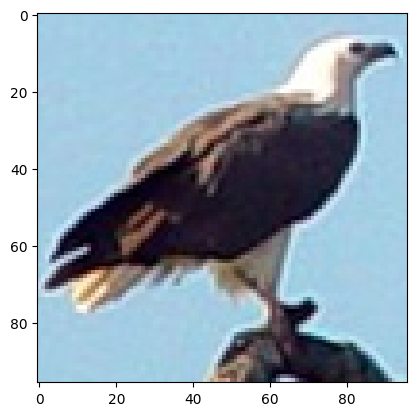

In [ ]:
import matplotlib.pyplot as plt
n = np.random.randint(0,test_images.shape[0])
plt.imshow(test_images[n])

Let us now visualize the puzzle

In [ ]:
def plot_puzzle(patches, ordering=None):
    """
    Plots jigsaw patches on a 96x96 canvas.

    Args:
        patches: Array of shape (9, 28, 28, 3)
        ordering: Optional array of shape (9,) or (1, 9) containing
                  the destination grid indices.
    """
    # 1. Handle ordering: if None, use [0, 1, 2... 8]
    if ordering is None:
        order = np.arange(9)
    else:
        order = np.array(ordering).flatten()

    # 2. Setup canvas (96x96x3)
    # Use 1.0 for float images (0.0-1.0) or 255 for uint8 images
    if patches.dtype == np.uint8:
        canvas = np.full((96, 96, 3), 255, dtype=np.uint8)
    else:
        canvas = np.ones((96, 96, 3), dtype=np.float32)

    cell_dim = 32
    patch_dim = 28
    margin = (cell_dim - patch_dim) // 2

    # 3. Place patches
    for i in range(9):
        # Determine destination grid position
        grid_pos = order[i]

        row = grid_pos // 3
        col = grid_pos % 3

        # Calculate canvas pixel coordinates
        y_start = (row * cell_dim) + margin
        y_end = y_start + patch_dim
        x_start = (col * cell_dim) + margin
        x_end = x_start + patch_dim

        # Insert patch i into its grid_pos
        canvas[y_start:y_end, x_start:x_end] = patches[i]

    # 4. Display
    plt.figure(figsize=(5, 5))
    plt.imshow(canvas)
    plt.axis('off')
    plt.show()


In [ ]:
a,b = test_generator.__getitem__(1)

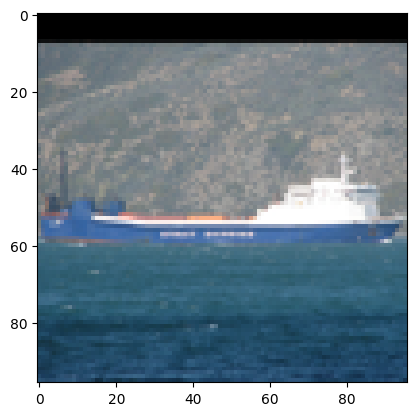

In [ ]:
plt.imshow(b[4])

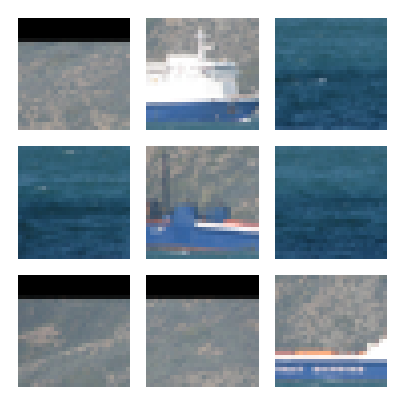

In [ ]:
plot_puzzle(a[4])

# The problem

Your task is to reconstruct the source (96,96) image from the set of 9 scambled patches of dimension (28,28) each.

**The metric used to measure the quality of the reconstruction must be Mean Absolute Error (MAE).**

Compute MAE over the test set, and also return the standard deviation.


As an indicative baseline, let us compute the MAE relative to the mean patches.

In [ ]:
def mean_patch_image(patches):
    #input (B,9,28,28,3)
    B = tf.shape(patches)[0] # Corrected: Use batch size from patches input
    # Mean patch
    mean_patch = tf.reduce_mean(patches, axis=1)  # (B, 28, 28, 3)
    # Replicate 9 times
    mean_patches = tf.repeat(
        mean_patch[:, None, :, :, :],
        repeats=9,
        axis=1
    )
    # Reassemble into 96x96 image
    out = tf.reshape(mean_patches, (B, 3, 3, 28, 28, 3))
    out = tf.transpose(out, [0, 1, 3, 2, 4, 5])
    out = tf.reshape(out, (B, 84, 84, 3))
    out = tf.image.resize(out, (96, 96))
    return out

In [ ]:
# Fixed permutations; use the same seed in the model evaluation.
np.random.seed(42)
baseline_maes = []

for i in range(len(test_generator)):
    x_batch, y_batch = test_generator[i]
    predictions = mean_patch_image(x_batch).numpy()
    image_maes = np.mean(np.abs(y_batch - predictions), axis=(1, 2, 3))
    baseline_maes.extend(image_maes)

baseline_maes = np.asarray(baseline_maes, dtype=np.float64)
print(f"Test images: {baseline_maes.size}")
print(f"Baseline MAE: {baseline_maes.mean():.5f}")
print(f"Baseline std (per image): {baseline_maes.std(ddof=0):.5f}")


Test images: 10000
Baseline MAE: 0.18237
Baseline std (per image): 0.05612


# Additional Constraints

* The solution must rely entirely on neural networks and must not contain non-neural algorithmic components. A pipeline of neural networks is allowed.
* Pretrained models are not permitted.
* The total number of trainable parameters must remain below 6 million. The number of parameters of the proposed solution must be reported explicitly.
* The model weights must be made available for download via gdown. Please verify that the provided link works correctly and that the weights can be loaded successfully.
* The solution must be implemented in Keras and must run on Google Colab. Submissions containing notebook execution errors will be penalized.
* The submission must be a single, well documented notebook file. Tar files will be rejected.





### SOLUTION

I chose to use a `batch_size` equal to 32. Furthermore, I substituted `images` with `train_images` in the `train_generator` initialization. Otherwise, this would have caused a data leakage problem.

### NN Architecture

The proposed architecture is divided into four core neural phases:

**1. Shared Feature Extraction (CNN):** A shared Convolutional Neural Network processes the 9 input patches. It utilizes convolutions and max pooling and a `Flatten` operation to extract latent tokens while explicitly preserving the high-frequency spatial edge awareness required for solving the eroded borders.

**2. Logical Reasoning (Transformer Encoder):** The unordered tokens are passed through a stack of Self-Attention Transformer blocks, allowing the network to build global context and reason about which visual features belong together.

**3. Jigsaw Decoder:** To avoid non-neural algorithmic sorting, the routing is handled purely via Cross-Attention. Learned `GridQueries` attend to the patch tokens to generate a continuous, differentiable attention weight matrix. The final canvas is assembled using a differentiable tensor operation (tf.einsum). In this operation, the spatial image patches act as the 'Values' in the attention mechanism, allowing the network to mathematically blend the puzzle pieces into their correct grid cells based on the learned attention weights.

**4. Final Reconstruction (U-Net Residual):** Because the assembled canvas contains eroded 4-pixel padding gaps, an efficient U-Net acts as the final generative step. It analyzes the spatial canvas and predicts a continuous `tanh` residual to heal the grid seams and hallucinate the missing textures.

**Parameters constraint:**
The total trainable parameter count for this architecture is approximately **3.7 million**, comfortably satisfying the `< 6,000,000` parameter constraint. Pretrained models are not utilized; all weights are initialized and trained from scratch.

```text
Input: 9 scrambled patches
        shape: (9, 28, 28, 3)
              │
              ▼
┌──────────────────────────────┐
│ Shared CNN Patch Encoder     │
│ same encoder for all patches │
└───────────────┬──────────────┘
                ▼
        Patch tokens
        shape: (9, 192)
                │
                ▼
┌──────────────────────────────┐
│ Transformer Reasoning Module │
│ self-attention among patches │
└───────────────┬──────────────┘
                ▼
      Context-aware patch tokens
                │
                ▼
┌──────────────────────────────┐
│ Learned Grid Queries         │
│ one query for each grid cell │
└───────────────┬──────────────┘
                ▼
┌──────────────────────────────┐
│ Neural Router                │
│ learns cell-to-patch weights │
└───────────────┬──────────────┘
                ▼
      Attention Weights
      shape: (9 cells, 9 patches)
                │
                ▼
┌──────────────────────────────┐
│ Neural Assembler Layer       │
│ attention-weighted canvas    │
└───────────────┬──────────────┘
                ▼
      Assembled 96×96 canvas
                │
                ▼
┌──────────────────────────────┐
│ Residual U-Net Refiner       │
│ fills seams and borders      │
└───────────────┬──────────────┘
                ▼
Output: reconstructed image
        shape: (96, 96, 3)
```


Regarding hyperparameters' choices:

**1. Transformer Configuration (embed_dim = 192, heads = 4)**:
The embedding dimension of 192 balances representational capacity and parameter efficiency; no ablation study is reported here. It is large enough to encode the complex high-frequency edge details extracted by the CNN, but small enough to strictly satisfy the `< 6M` parameter constraint. Using 4 attention heads divides the embedding into 48-dimensional subspaces, allowing the self-attention mechanism to simultaneously evaluate different logical rules (e.g., color continuity, edge shape, and global texture) without introducing excessive computational overhead.

**2. Entropy Regularization Weight (entropy_weight = 1e-2)**:
 The entropy penalty encourages concentrated attention distributions, but does not guarantee one-to-one routing. Its weight is `0.01`; no ablation study is reported here.


**3. U-Net Refiner Residual Output (tanh activation)**:
Instead of predicting raw pixel values (0 to 1) using a Sigmoid activation, the final U-Net layer uses a `tanh` activation (outputting values between -1 and 1). This is a crucial design choice: it allows the network to  actively add or subtract color intensity to repair the eroded borders of the assembled canvas, rather than completely overwriting the CNN's work.

**4. Soft Column Penalty (penalty_weight = 0.5)**
Inside `NeuralRouter`, an auxiliary loss (`col_penalty`) encourages the columns of the attention matrix to sum to 1.0. Softmax normalizes each row but allows patch mixtures. The column penalty encourages balanced patch use; it does not guarantee that every patch is used exactly once. A weight of `0.5` balances this constraint against the primary reconstruction loss.

In [ ]:
@keras.saving.register_keras_serializable(package="jigsaw")
class GridQueries(layers.Layer):
    def __init__(self, num=9, dim=192, **kw):
        super().__init__(**kw)
        self.num = num
        self.dim = dim

    def build(self, s):
        self.table = self.add_weight(shape=(self.num, self.dim),
                                     initializer="glorot_uniform",
                                     trainable=True,
                                     name="table")

    def call(self, ref):
        b = tf.shape(ref)[0]
        return tf.tile(tf.expand_dims(self.table, 0), [b, 1, 1])

    def compute_output_shape(self, s):
        return (s[0], self.num, self.dim)

    def get_config(self):
        c = super().get_config()
        c.update(num=self.num, dim=self.dim)
        return c



@keras.saving.register_keras_serializable(package="jigsaw")
class NeuralRouter(layers.Layer):
    def __init__(self, penalty_weight=0.5, **kw):
        super().__init__(**kw)
        self.penalty_weight = penalty_weight

    def call(self, inputs):
        slots, tokens = inputs
        d = tf.cast(tf.shape(slots)[-1], tf.float32)
        scores = tf.matmul(slots, tokens, transpose_b=True) / tf.sqrt(d)

        attention_weights = tf.nn.softmax(scores, axis=-1)

        col_sums = tf.reduce_sum(attention_weights, axis=1)
        col_penalty = tf.reduce_mean(tf.square(col_sums - 1.0))
        self.add_loss(self.penalty_weight * col_penalty)

        return attention_weights

    def compute_output_shape(self, s):
        return (s[0][0], s[0][1], s[1][1])

    def get_config(self):
        c = super().get_config()
        c.update(penalty_weight=self.penalty_weight)
        return c

@keras.saving.register_keras_serializable(package="jigsaw")
class NeuralAssembler(layers.Layer):
    def call(self, inputs):
        attention_weights, patches = inputs

        cells = tf.einsum("bcp,bphwk->bchwk", attention_weights, patches)
        cells = tf.pad(cells, [[0,0],[0,0],[2,2],[2,2],[0,0]])
        B = tf.shape(cells)[0]
        g = tf.reshape(cells, (B, 3, 3, 32, 32, 3))
        g = tf.transpose(g, [0, 1, 3, 2, 4, 5])
        return tf.reshape(g, (B, 96, 96, 3))

    def compute_output_shape(self, s):
        return (s[1][0], 96, 96, 3)

@keras.saving.register_keras_serializable(package="jigsaw")
class EntropyReg(layers.Layer):
    def __init__(self, weight=1e-2, **kw): super().__init__(**kw); self.weight = weight

    def call(self, attention_weights):
        ent = -tf.reduce_sum(attention_weights * tf.math.log(attention_weights + 1e-8), axis=-1)
        self.add_loss(self.weight * tf.reduce_mean(ent))
        return attention_weights

    def get_config(self):
        c = super().get_config(); c["weight"] = self.weight; return c

@keras.saving.register_keras_serializable(package="jigsaw")
class ClipReconstruction(layers.Layer):
    def call(self, inputs):
        canvas, residual = inputs
        return tf.clip_by_value(canvas + residual, 0.0, 1.0)
    def compute_output_shape(self, s): return s[0]


# ENCODER AND TRANSFORMER
def patch_encoder(crop=28, embed_dim=192, name="patch_encoder"):
    inp = keras.Input((crop, crop, 3))
    x = layers.Conv2D(48,3,padding="same",use_bias=True)(inp); x=layers.LayerNormalization()(x); x=layers.Activation("relu")(x)
    x = layers.Conv2D(48,3,padding="same",use_bias=True)(x);   x=layers.LayerNormalization()(x); x=layers.Activation("relu")(x)
    x = layers.MaxPool2D()(x)
    x = layers.Conv2D(96,3,padding="same",use_bias=True)(x);   x=layers.LayerNormalization()(x); x=layers.Activation("relu")(x)
    x = layers.Conv2D(96,3,padding="same",use_bias=True)(x);   x=layers.LayerNormalization()(x); x=layers.Activation("relu")(x)
    x = layers.MaxPool2D()(x)
    x = layers.Conv2D(160,3,padding="same",use_bias=True)(x);  x=layers.LayerNormalization()(x); x=layers.Activation("relu")(x)

    x = layers.Flatten()(x)
    x = layers.Dense(embed_dim, activation="relu")(x)
    return keras.Model(inp, x, name=name)

def transformer_block(x, dim, heads=4, name="tb"):
    a = layers.MultiHeadAttention(heads, dim//heads, name=name+"_mha")(x, x)
    x = layers.Add()([x, a]); x = layers.LayerNormalization(name=name+"_ln1")(x)
    m = layers.Dense(dim*2, activation="gelu", name=name+"_mlp1")(x)
    m = layers.Dense(dim, name=name+"_mlp2")(m)
    x = layers.Add()([x, m]); x = layers.LayerNormalization(name=name+"_ln2")(x)
    return x

# U-NET REFINEMENT
def refine_unet_residual(canvas):
    def CN(t, f):
        t = layers.Conv2D(f,3,padding="same",use_bias=True)(t)
        t = layers.LayerNormalization()(t); return layers.Activation("relu")(t)
    c1 = CN(CN(canvas,48),48); p1 = layers.MaxPool2D()(c1)
    c2 = CN(CN(p1,96),96);     p2 = layers.MaxPool2D()(c2)
    c3 = CN(CN(p2,160),160)
    u2 = layers.UpSampling2D()(c3); u2 = layers.Concatenate()([u2,c2]); d2 = CN(CN(u2,96),96)
    u1 = layers.UpSampling2D()(d2); u1 = layers.Concatenate()([u1,c1]); d1 = CN(CN(u1,48),48)
    return layers.Conv2D(3,3,padding="same",activation="tanh",name="residual")(d1)


# FINAL MODEL INTEGRATION
def build_jigsaw_model(embed_dim=192, heads=4, entropy_weight=1e-2):
    patches = keras.Input((9,28,28,3), name="scrambled_patches")

    enc = patch_encoder(embed_dim=embed_dim)
    tokens = layers.TimeDistributed(enc, name="td_encoder")(patches)

    x = transformer_block(tokens, embed_dim, heads, "tb1")
    x = transformer_block(x,      embed_dim, heads, "tb2")
    x = transformer_block(x,      embed_dim, heads, "tb3")

    queries = GridQueries(9, embed_dim, name="grid_queries")(tokens)

    slots = layers.MultiHeadAttention(num_heads=heads, key_dim=embed_dim//heads, name="cross_attention")(queries, x)
    slots = layers.Add()([queries, slots])
    slots = layers.LayerNormalization(name="slots_ln")(slots)

    attention_weights = NeuralRouter(name="neural_router")([slots, tokens])
    attention_weights = EntropyReg(entropy_weight, name="entropy_reg")(attention_weights)

    canvas = NeuralAssembler(name="assemble")([attention_weights, patches])

    residual = refine_unet_residual(canvas)
    out = ClipReconstruction(name="reconstruction")([canvas, residual])

    return keras.Model(patches, out, name="Jigsaw_Model")


keras.utils.clear_session()
model = build_jigsaw_model()
model.summary()

trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"\nTotal trainable parameters: {trainable:,}")
assert trainable < 6_000_000, "Constraint Violated!"
print("Constraint (< 6,000,000): SATISFIED")


Model: "Jigsaw_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ scrambled_patches   │ (None, 9, 28, 28, │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ td_encoder          │ (None, 9, 192)    │  1,791,504 │ scrambled_patche… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb1_mha             │ (None, 9, 192)    │    148,224 │ td_encoder[0][0], │
│ (MultiHeadAttentio… │                   │            │ td_encoder[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 9, 192)    │          0 │ td_encoder[0][0], │
│                     │                   │            │ tb1_mha[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb1_ln1             │ (None, 9, 192)    │        384 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb1_mlp1 (Dense)    │ (None, 9, 384)    │     74,112 │ tb1_ln1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb1_mlp2 (Dense)    │ (None, 9, 192)    │     73,920 │ tb1_mlp1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 9, 192)    │          0 │ tb1_ln1[0][0],    │
│                     │                   │            │ tb1_mlp2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb1_ln2             │ (None, 9, 192)    │        384 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb2_mha             │ (None, 9, 192)    │    148,224 │ tb1_ln2[0][0],    │
│ (MultiHeadAttentio… │                   │            │ tb1_ln2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 9, 192)    │          0 │ tb1_ln2[0][0],    │
│                     │                   │            │ tb2_mha[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb2_ln1             │ (None, 9, 192)    │        384 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb2_mlp1 (Dense)    │ (None, 9, 384)    │     74,112 │ tb2_ln1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb2_mlp2 (Dense)    │ (None, 9, 192)    │     73,920 │ tb2_mlp1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 9, 192)    │          0 │ tb2_ln1[0][0],    │
│                     │                   │            │ tb2_mlp2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb2_ln2             │ (None, 9, 192)    │        384 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb3_mha             │ (None, 9, 192)    │    148,224 │ tb2_ln2[0][0],    │
│ (MultiHeadAttentio… │                   │            │ tb2_ln2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 9, 192)    │          0 │ tb2_ln2[0][0],    │
│                     │                   │            │ tb3_mha[0][0]   

 Total params: 3,739,059 (14.26 MB)

 Trainable params: 3,739,059 (14.26 MB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters: 3,739,059
Constraint (< 6,000,000): SATISFIED


### Training Strategy

The network is trained with the primary objective of explicitly minimizing the **Mean Absolute Error (MAE)**, as required by the project guidelines. To ensure the model achieves the lowest possible MAE, the following training recipe is implemented:

**1. Boundary-Aware Loss Function**:
To train this architecture I used a custom `boundary_aware_mae` loss:
* **Global Layout:** Computes the standard Mean Absolute Error (MAE) between the predicted canvas and the ground truth.
* **Penalty:** Applies Sobel edge-detection filters to both the prediction and the ground truth. It extracts the high-frequency spatial gradients and heavily penalizes mismatched borders. This forces the U-Net to prioritize visually consistent edges.

**2. Optimization and Learning Rate Schedule**:
* **Optimizer:** The model uses `AdamW` (Adam with Weight Decay set to 1e-4). This heavily regularizes the U-Net and Transformer layers, forcing them to learn generalized puzzle logic rather than memorizing the specific pixels of the training set.
* **Learning Rate Schedule:** A custom `WarmupCosineDecay` is employed. The learning rate linearly warms up from zero for the first 3 epochs to a maximum of 3e-4. This prevents the Cross-Attention router from diverging randomly at the start of training. After warmup, the learning rate follows a smooth cosine curve downward over the total epochs, allowing for highly precise micro-adjustments at the end of training. This was preferred over the implementation of a `ReduceLROnPlateau` callback.

**3. Regularization & Callbacks**:
To monitor validation performance and retain the best checkpoint, the training loop uses the following callbacks:
* **Early Stopping:** Actively monitors the unseen validation MAE. If the network stops improving for 10 consecutive epochs, training halts early and the best weights are automatically restored.
* **Dynamic Checkpointing:** The absolute lowest-error state of the model is continuously saved to `best_jigsaw.weights.h5`, ensuring the final evaluation uses the overall best performance.

In [ ]:
# Learning-rate schedule
EPOCHS       = 60
WARMUP_STEPS = len(train_generator) * 3          # 3 warm-up epochs
TOTAL_STEPS  = len(train_generator) * EPOCHS
LR_BASE      = 3e-4

@keras.saving.register_keras_serializable(package="jigsaw")
def boundary_aware_mae(y_true, y_pred):
    pixel_error = tf.reduce_mean(tf.abs(y_true - y_pred))

    true_gradients = tf.image.sobel_edges(y_true)
    pred_gradients = tf.image.sobel_edges(y_pred)

    penalty = tf.reduce_mean(tf.abs(true_gradients - pred_gradients))

    return pixel_error + 0.15 * penalty

@keras.saving.register_keras_serializable(package="jigsaw")
class WarmupCosineDecay(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, base_lr, warmup_steps, total_steps):
        super().__init__()
        self.base_lr      = base_lr
        self.warmup_steps = warmup_steps
        self.total_steps  = total_steps

    def __call__(self, step):
        step   = tf.cast(step, tf.float32)
        warmup = self.base_lr * (step / self.warmup_steps)
        decay  = self.base_lr * 0.5 * (
            1.0 + tf.cos(
                np.pi * (step - self.warmup_steps) /
                tf.cast(self.total_steps - self.warmup_steps, tf.float32)
            )
        )
        return tf.where(step < self.warmup_steps, warmup, decay)

    def get_config(self):
        return {
            "base_lr":      self.base_lr,
            "warmup_steps": self.warmup_steps,
            "total_steps":  self.total_steps,
        }


lr_schedule = WarmupCosineDecay(LR_BASE, WARMUP_STEPS, TOTAL_STEPS)
optimizer   = keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4)

model.compile(
    optimizer = optimizer,
    loss      = boundary_aware_mae,
    metrics   = [keras.metrics.MeanAbsoluteError(name="mae")],
)

# Callbacks
CHECKPOINT_PATH = "best_jigsaw.weights.h5"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        CHECKPOINT_PATH,
        monitor="val_mae",
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_mae",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.TerminateOnNaN(),
]

TRAIN_MODEL = False # Set this to True to make training start

if TRAIN_MODEL:
    history = model.fit(
        train_generator,
        validation_data = val_generator,
        epochs          = EPOCHS,
        callbacks       = callbacks,
        verbose         = 1,
    )



### Visualizations of Training Curves

**Historical training curves.** Preserved from the original training run; no retraining was performed. This image remains visible when running all cells.


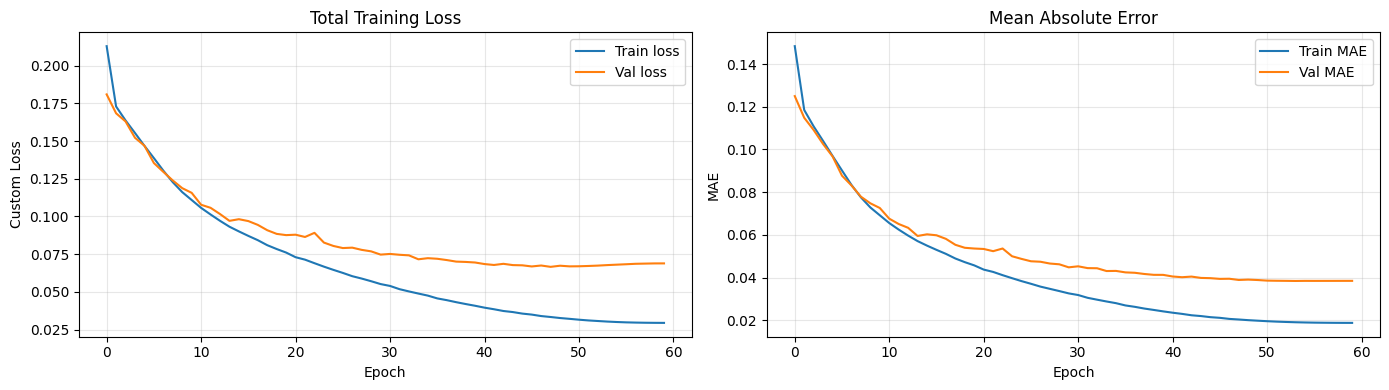


The saved curves document the original training run:
* Training and validation errors decrease substantially during the early epochs.
* Validation MAE plateaus while training MAE continues to decrease, indicating a generalization gap.
* Checkpointing selects the lowest validation-MAE checkpoint. This limits degradation after the best epoch but does not guarantee absence of overfitting or establish that the learning-rate schedule is optimal.

These curves are retained from the previous run. They do not need to be regenerated for inference-only evaluation.


### Loading of the weights

Load the existing trained checkpoint; no retraining is needed. The cell uses `best_jigsaw.weights.h5` when it exists locally; otherwise it uses the original Google Drive file. Confirm that the downloaded file is your intended best checkpoint. The link and weight loading have not been reverified during this edit.


In [ ]:
!pip install gdown -q

import gdown

WEIGHTS_LOADED = False
FILE_ID = "1i44PssbOpJ6xczLpGgykk5GyxYXNWO8W"
LOCAL_PATH = "best_jigsaw.weights.h5"
DEST_PATH = "downloaded_jigsaw_lm.weights.h5"

if os.path.isfile(LOCAL_PATH):
    weights_path = LOCAL_PATH
else:
    if not os.path.isfile(DEST_PATH):
        downloaded = gdown.download(
            f"https://drive.google.com/uc?id={FILE_ID}", DEST_PATH, quiet=False
        )
        if downloaded is None:
            raise RuntimeError("Download failed. Upload the existing best_jigsaw.weights.h5 checkpoint.")
    weights_path = DEST_PATH

model = build_jigsaw_model()
model.load_weights(weights_path)
WEIGHTS_LOADED = True
print(f"Existing trained weights loaded from: {weights_path}")


Downloading...
From: https://drive.google.com/uc?id=1i44PssbOpJ6xczLpGgykk5GyxYXNWO8W
To: /content/downloaded_jigsaw_lm.weights.h5
100%|██████████| 45.2M/45.2M [00:00<00:00, 79.1MB/s]


Existing trained weights loaded from: downloaded_jigsaw_lm.weights.h5


### Load Best Weights & Evaluate on Test Set

The preceding cell must successfully load the existing trained checkpoint before evaluation.

Compute one MAE per test image over its normalized RGB pixels, then report the mean and population standard deviation (`ddof=0`) across individual test images. This gives equal weight to every image, including the final partial batch. Standard deviation describes image-to-image variation, not a confidence interval or proof that all puzzles are reconstructed well.

Baseline and model evaluation reset the same NumPy seed and use the non-shuffled test generator, producing the same sequence of puzzles in these sequential loops.

**Historical results, before this correction:** model MAE `0.03880` and standard deviation `0.00804` were calculated over batch means. The original baseline used cumulative metric values. These are not corrected per-image results; rerun the two evaluation cells with the existing weights to obtain the updated numbers. No training is required.


In [ ]:
assert globals().get("WEIGHTS_LOADED", False), (
    "Load the existing trained weights before evaluation."
)

np.random.seed(42)
model_maes = []

for i in range(len(test_generator)):
    x_batch, y_batch = test_generator[i]
    predictions = model.predict(x_batch, verbose=0)
    image_maes = np.mean(np.abs(y_batch - predictions), axis=(1, 2, 3))
    model_maes.extend(image_maes)

model_maes = np.asarray(model_maes, dtype=np.float64)
test_mae = model_maes.mean()
test_std = model_maes.std(ddof=0)

print(f"Test images: {model_maes.size}")
print(f"Test MAE: {test_mae:.5f}")
print(f"Test std (per image): {test_std:.5f}")

if "baseline_maes" in globals():
    assert baseline_maes.size == model_maes.size
    baseline_mean = baseline_maes.mean()
    if baseline_mean > 0:
        improvement = 100 * (baseline_mean - test_mae) / baseline_mean
        print(f"MAE reduction vs baseline: {improvement:.2f}%")


Test images: 10000
Test MAE: 0.03875
Test std (per image): 0.04802
MAE reduction vs baseline: 78.75%


### Qualitative Results
The saved examples below are retained from the original test run. Rerun the plotting cell after loading the weights to refresh them. They illustrate reconstruction quality but are not a representative statistical sample of the full test set.


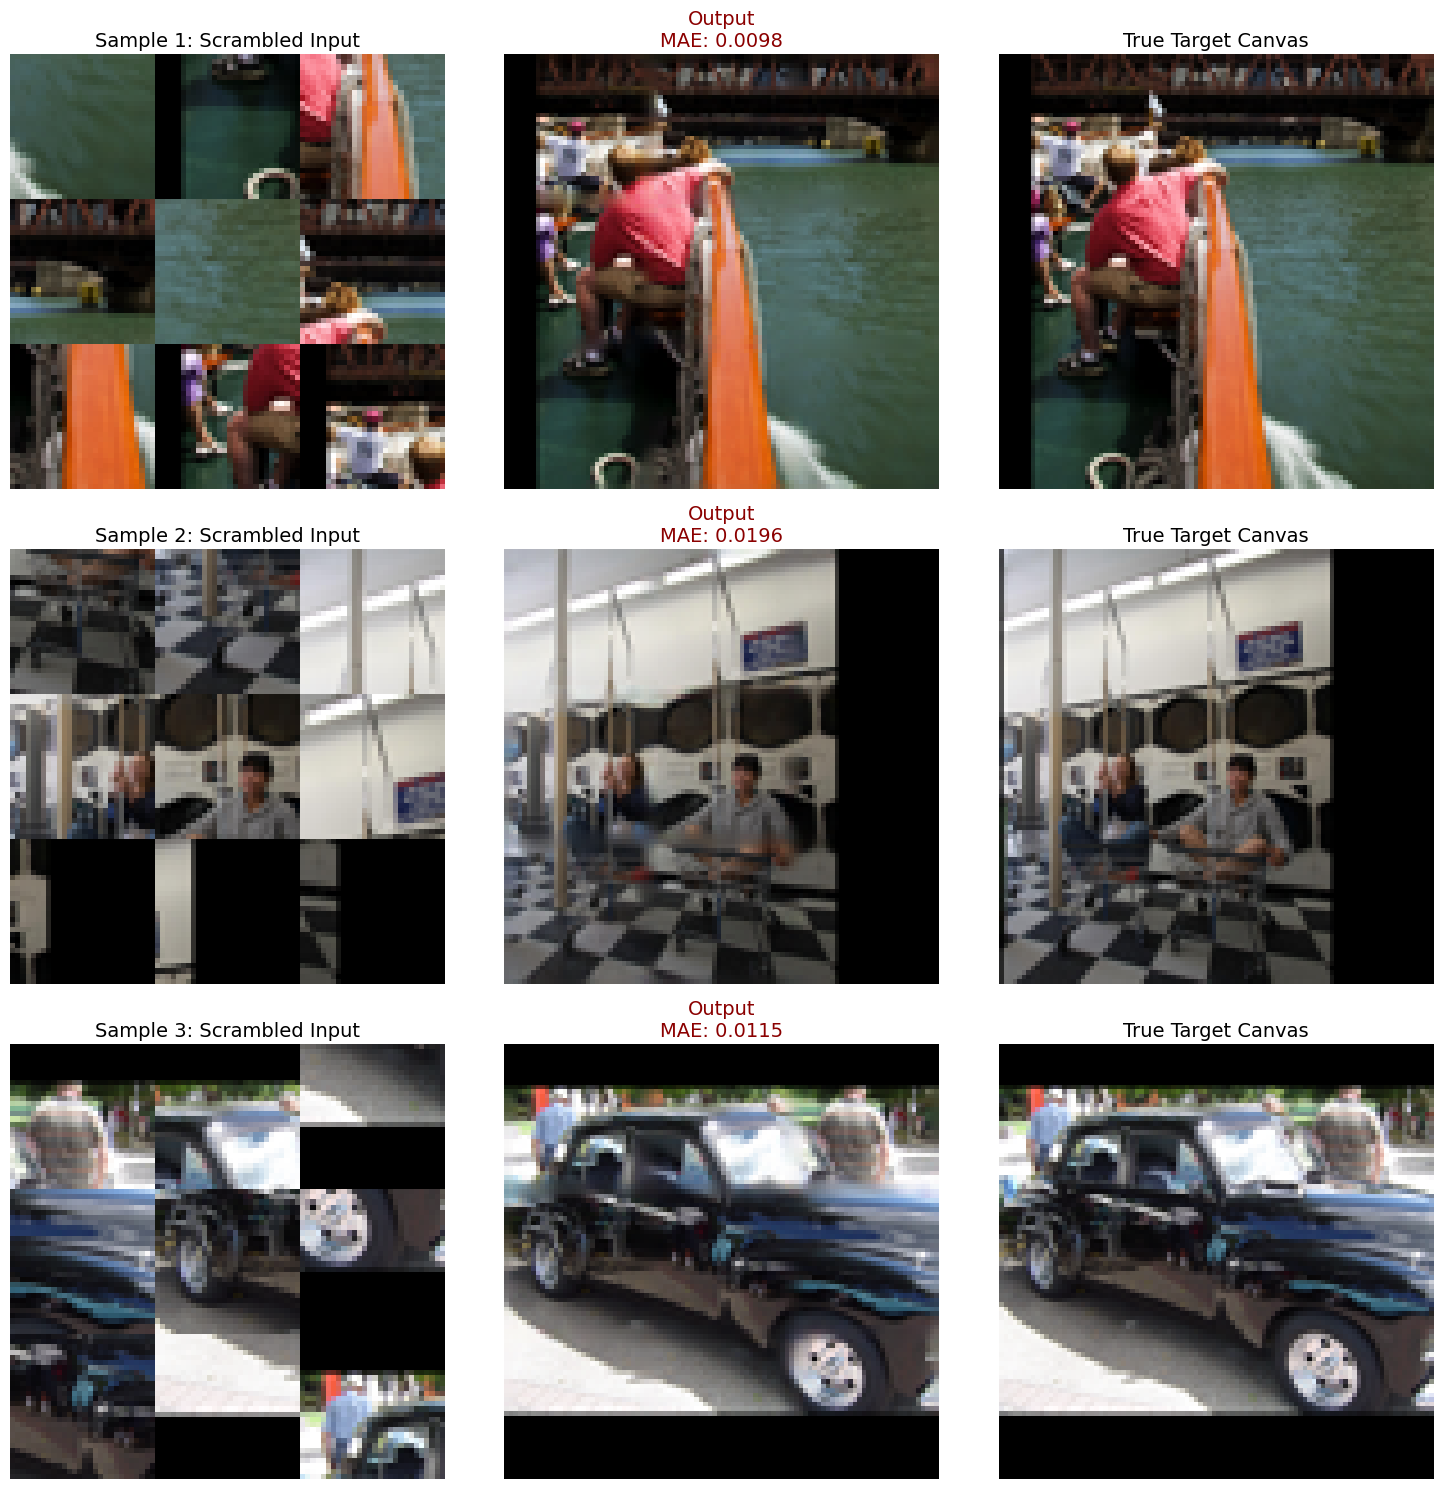

In [ ]:
def plot_jigsaw_results(model, test_gen, num_samples=3):
    x_val, y_val = next(iter(test_gen))

    predictions = model.predict(x_val, verbose=0)

    plt.figure(figsize=(15, 5 * num_samples))

    for i in range(num_samples):
        mae = np.mean(np.abs(y_val[i] - predictions[i]))

        # Plot Scrambled Patches (Input)
        plt.subplot(num_samples, 3, i * 3 + 1)
        # Arrange the 9 patches into a rough 3x3 grid for visualization
        scrambled_grid = np.zeros((28*3, 28*3, 3))
        for j in range(9):
            row, col = j // 3, j % 3
            scrambled_grid[row*28:(row+1)*28, col*28:(col+1)*28, :] = x_val[i, j]

        plt.imshow(np.clip(scrambled_grid, 0, 1))
        plt.title(f"Sample {i+1}: Scrambled Input", fontsize=14)
        plt.axis("off")

        # Plot Model Output (Reconstruction)
        plt.subplot(num_samples, 3, i * 3 + 2)
        plt.imshow(np.clip(predictions[i], 0, 1))
        plt.title(f"Output\nMAE: {mae:.4f}", fontsize=14, color="darkred")
        plt.axis("off")

        # Plot Ground Truth (Target)
        plt.subplot(num_samples, 3, i * 3 + 3)
        plt.imshow(np.clip(y_val[i], 0, 1))
        plt.title("True Target Canvas", fontsize=14)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

plot_jigsaw_results(model, test_generator, num_samples=3)